# ECE 9603/9063 - Data Analytics Foundations
## Assignment 1: Forecasting - Exploratory Data Analysis (EDA)

This notebook explores the **UCI Bike Sharing Dataset** (`data/hour.csv`).
We investigate:
1. Dataset dimensions, attributes, and missing values.
2. Proper feature selection and target isolation (preventing target leakage).
3. Summary statistics (mean, std, percentiles) for the report.
4. Circadian commuting patterns (working days vs. weekends/holidays).

### Step 1: Load Data & Inspect Dimensions

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Handle path flexibly whether run from workspace root or notebooks directory
data_path = os.path.join("data", "hour.csv") if os.path.exists(os.path.join("data", "hour.csv")) else os.path.join("..", "data", "hour.csv")
df = pd.read_csv(data_path)
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset Dimensions: 17379 rows, 17 columns


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### Step 2: Check for Missing Values & Column Types

In [2]:
print("Missing values check:")
print(df.isnull().sum())
print("\nData Types:")
print(df.dtypes)

Missing values check:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Data Types:
instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object


### Step 3: Feature Selection (Avoiding Target Leakage)
* Drop `instant` (arbitrary index) and `dteday` (redundant date string).
* Drop `casual` and `registered` because `cnt = casual + registered`. Including them would introduce **target leakage**.

In [3]:
feature_cols = [
    'season', 'yr', 'mnth', 'hr', 'holiday', 
    'weekday', 'workingday', 'weathersit', 
    'temp', 'atemp', 'hum', 'windspeed'
]
target_col = 'cnt'

X = df[feature_cols]
y = df[target_col]

print(f"X shape: {X.shape}, y shape: {y.shape}")

X shape: (17379, 12), y shape: (17379,)


### Step 4: Summary Statistics Table (For Academic Report)

In [4]:
summary_cols = ['temp', 'atemp', 'hum', 'windspeed', 'cnt']
stats_table = df[summary_cols].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
stats_table.columns = ['Mean', 'Std Dev', 'Min', 'Q1 (25%)', 'Median (50%)', 'Q3 (75%)', 'Max']
stats_table

,Mean,Std Dev,Min,Q1 (25%),Median (50%),Q3 (75%),Max
temp,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000
atemp,0.475775,0.171850,0.00,0.3333,0.4848,0.6212,1.0000
hum,0.627229,0.192930,0.00,0.4800,0.6300,0.7800,1.0000
windspeed,0.190098,0.122340,0.00,0.1045,0.1940,0.2537,0.8507
cnt,189.463088,181.387599,1.00,40.0000,142.0000,281.0000,977.0000


### Step 5: Visualize Hourly Demand Profile (Commute Spikes vs Leisure Curve)
Notice the bimodal distribution on working days (peaks at 8 AM and 5 PM) versus the unimodal curve on weekends.

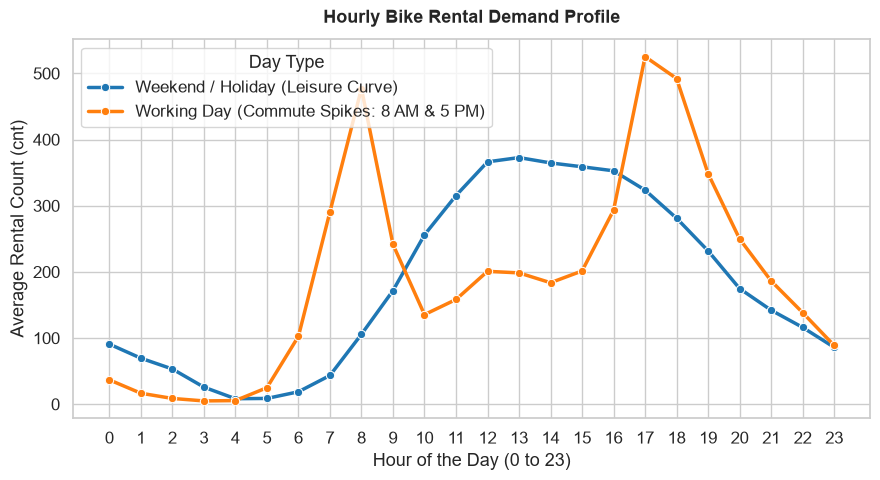

In [5]:
sns.set_theme(style="whitegrid", font_scale=1.1)

hourly_pattern = df.groupby(['hr', 'workingday'])['cnt'].mean().reset_index()
hourly_pattern['Day Type'] = hourly_pattern['workingday'].map({
    1: 'Working Day (Commute Spikes: 8 AM & 5 PM)',
    0: 'Weekend / Holiday (Leisure Curve)'
})

plt.figure(figsize=(9, 5))
sns.lineplot(
    data=hourly_pattern,
    x='hr',
    y='cnt',
    hue='Day Type',
    marker='o',
    linewidth=2.5,
    palette=['#1f77b4', '#ff7f0e']
)
plt.title("Hourly Bike Rental Demand Profile", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Hour of the Day (0 to 23)")
plt.ylabel("Average Rental Count (cnt)")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()